# Bab 3 — Statistical Experiments and Significance Testing

**Rujukan:** buku utama edisi 2, Bab 3. Dataset `web_page_data.csv`, `four_sessions.csv`, dan `click_rates.csv` dari repositori pendamping resmi. Kode dan uraian merupakan implementasi mandiri. Nilai-p menjawab pertanyaan tentang data *jika hipotesis nol benar*, bukan probabilitas hipotesis nol benar.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
rng = np.random.default_rng(42)
web = pd.read_csv(ROOT / 'data' / 'web_page_data.csv')
web.groupby('Page')['Time'].agg(['count', 'mean', 'median']).round(3)

mkdir -p failed for path C:\Users\Rangga Timotius\AppData\Local\matplotlib: [WinError 5] Access is denied: 'C:\\Users\\Rangga Timotius\\AppData\\Local\\matplotlib'


Matplotlib created a temporary cache directory at C:\Users\RANGGA~1\AppData\Local\Temp\matplotlib-yssp9ytp because there was an issue with the default path (C:\Users\Rangga Timotius\AppData\Local\matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


,count,mean,median
Page,,,
Page A,21,1.263,0.95
Page B,15,1.620,1.47


## 1. A/B test, hipotesis dan randomisasi

Dalam A/B test, unit eksperimen dialokasikan acak ke perlakuan A/B. Hipotesis nol $H_0$ dapat berupa tidak ada perbedaan mean; hipotesis alternatif menyatakan ada perbedaan. Randomisasi membantu memisahkan efek perlakuan dari karakteristik unit, asalkan eksperimentasi dilakukan dengan baik. Dataset kecil ini dipakai untuk mendemonstrasikan perhitungan, bukan untuk membuat keputusan produk.

In [2]:
a = web.loc[web.Page == 'Page A', 'Time'].to_numpy()
b = web.loc[web.Page == 'Page B', 'Time'].to_numpy()
observed = b.mean() - a.mean()
print('Mean B - A:', round(observed, 4), 'detik')
assert len(a) > 0 and len(b) > 0

Mean B - A: 0.3567 detik


## 2. Permutation test dan nilai-p

Di bawah $H_0$ bahwa label A/B dapat dipertukarkan, acak ulang label sambil mempertahankan ukuran grup. Statistik uji adalah selisih mean. Nilai-p dua sisi Monte Carlo dihitung sebagai proporsi permutasi dengan $|T^*|\ge|T_{obs}|$, memakai koreksi +1 agar tidak tepat nol. Kesimpulan bergantung pada desain dan asumsi *exchangeability*. Efek dan interval kepercayaan tetap penting meskipun nilai-p kecil.

Permutation p-value (two-sided): 0.2709


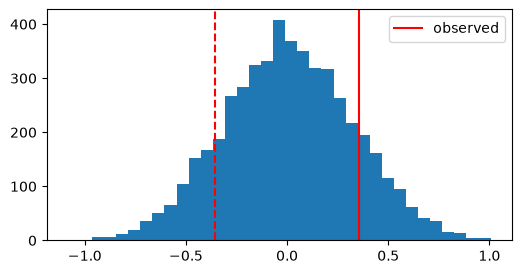

In [3]:
combined = np.concatenate([a, b])
permuted = np.empty(5000)
for i in range(len(permuted)):
    shuffle = rng.permutation(combined)
    permuted[i] = shuffle[len(a):].mean() - shuffle[:len(a)].mean()
p_perm = (1 + np.count_nonzero(np.abs(permuted) >= abs(observed))) / (len(permuted) + 1)
print('Permutation p-value (two-sided):', round(p_perm, 4))
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(permuted, bins=35); ax.axvline(observed, color='red', label='observed')
ax.axvline(-observed, color='red', linestyle='--'); ax.legend(); plt.show()

## 3. t-test, Type I/II error, dan power

Welch t-test membandingkan mean dua grup tanpa mengasumsikan varians sama. Type I error: menolak $H_0$ yang benar; Type II: gagal menolak $H_0$ yang salah. Power = peluang mendeteksi efek tertentu dengan desain dan aturan uji yang ditentukan. Perkiraan $n$ di bawah adalah pendekatan normal dua-sampel dengan ukuran grup sama, bukan perhitungan desain lengkap.

In [4]:
t_result = stats.ttest_ind(a, b, equal_var=False)
print('Welch t statistic:', round(t_result.statistic, 3), 'p:', round(t_result.pvalue, 4))
alpha, target_power, effect, sigma = .05, .80, .25, 1.0
z_alpha = stats.norm.ppf(1 - alpha / 2)
z_beta = stats.norm.ppf(target_power)
n_per_group = np.ceil(2 * (z_alpha + z_beta)**2 * sigma**2 / effect**2)
print('Approximate n/group for standardized effect 0.25:', int(n_per_group))

Welch t statistic: -1.098 p: 0.2815
Approximate n/group for standardized effect 0.25: 252


## 4. Multipel pengujian

Jika banyak hipotesis diuji pada ambang 0,05, peluang setidaknya satu false positive meningkat. Bonferroni mengontrol family-wise error rate dengan ambang $\alpha/m$. Benjamini–Hochberg (BH) menargetkan false discovery rate dalam kondisi yang sesuai. Nilai-p contoh di bawah hanya ilustrasi mekanik; tidak berasal dari lima eksperimen nyata.

In [5]:
p_values = np.array([.002, .018, .04, .11, .72])
m = len(p_values)
order = np.argsort(p_values)
ranked = p_values[order]
bonferroni = p_values <= .05 / m
bh_cutoff = np.arange(1, m+1) * .05 / m
valid = np.flatnonzero(ranked <= bh_cutoff)
bh = np.zeros(m, dtype=bool)
if len(valid): bh[order[:valid[-1]+1]] = True
print(pd.DataFrame({'p': p_values, 'Bonferroni': bonferroni, 'BH': bh}))

       p  Bonferroni     BH
0  0.002        True   True
1  0.018       False   True
2  0.040       False  False
3  0.110       False  False
4  0.720       False  False


## 5. ANOVA dan chi-square

ANOVA satu arah menguji apakah semua mean kelompok sama, dengan rasio variasi antar- dan dalam-kelompok. Uji F memerlukan perhatian pada independensi, bentuk residual, dan homogenitas varians. Untuk data hitungan kategoris, chi-square menguji independensi pada tabel kontingensi; frekuensi harapan kecil dapat membuat pendekatan asimtotik buruk, sehingga prosedur exact/alternatif dibutuhkan. Hasil signifikan tidak menunjukkan pasangan mana yang berbeda tanpa analisis lanjutan.

In [6]:
sessions = pd.read_csv(ROOT / 'data' / 'four_sessions.csv')
groups = [group['Time'].to_numpy() for _, group in sessions.groupby('Page')]
anova = stats.f_oneway(*groups)
print('ANOVA F:', round(anova.statistic, 3), 'p:', round(anova.pvalue, 4))
clicks = pd.read_csv(ROOT / 'data' / 'click_rates.csv')
table = clicks.pivot(index='Headline', columns='Click', values='Rate')
chi2, p_chi2, dof, expected = stats.chi2_contingency(table)
print(table)
print('Chi-square:', round(chi2, 3), 'p:', round(p_chi2, 4), 'min expected:', round(expected.min(), 2))

ANOVA F: 2.74 p: 0.0776
Click       Click  No-click
Headline                   
Headline A     14       986
Headline B      8       992
Headline C     12       988
Chi-square: 1.666 p: 0.4348 min expected: 11.33


## 6. Multi-arm bandit (simulasi tambahan)

Bandit mengalokasikan lebih banyak traffic ke opsi yang tampak baik sambil terus mengeksplorasi. Kebijakan epsilon-greedy memilih arm acak dengan peluang $\epsilon$, selebihnya arm dengan rata-rata reward tertinggi saat ini. Ini berbeda dari A/B test tetap: alokasi adaptif mengubah analisis inferensinya. Angka reward di bawah **sintetis**, bukan data buku.

In [7]:
true_ctr = np.array([.04, .06, .05])
count = np.zeros(3, dtype=int); reward = np.zeros(3, dtype=int)
for _ in range(3000):
    arm = rng.integers(3) if rng.random() < .1 or not np.all(count) else np.argmax(reward / count)
    count[arm] += 1
    reward[arm] += rng.random() < true_ctr[arm]
print(pd.DataFrame({'true_CTR': true_ctr, 'visits': count, 'observed_CTR': reward/count}))

   true_CTR  visits  observed_CTR
0      0.04     409      0.041565
1      0.06    2491      0.065034
2      0.05     100      0.040000


### Ringkasan dan refleksi

- Rancang randomisasi, ukuran sampel, outcome utama, dan aturan berhenti sebelum melihat hasil.
- Nilai-p bukan ukuran efek, probabilitas $H_0$, maupun jaminan replikasi.
- Banyak uji membutuhkan kontrol kesalahan; keputusan sebaiknya memakai ukuran efek dan ketidakpastian.
- Bandit mengoptimalkan alokasi reward, sedangkan eksperimen klasik terutama mengestimasi efek; keduanya punya tujuan berbeda.